<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebook/06_Classification_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. MOUNT GOOGLE DRIVE & SETUP PATHS
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"
else:
    DATA = "../data"

PROFILE = f"{DATA}/profile"
CLEAN_DIR = f"{DATA}/clean"
DEMAND_LABELS = ["Low", "Medium", "High"]

# -------------------------------------------------------------
# 2. STEP 1: CONSTRUCT WINDOWED MONTHLY SAMPLES (MAY-OCTOBER ONLY)
# -------------------------------------------------------------
print("Compiling monthly windowed data (May-October only)...")
clean_files = sorted(glob.glob(f"{CLEAN_DIR}/clean_ridership_*.csv"))

monthly_samples = []
for path in clean_files:
    filename = os.path.basename(path)
    # Extract year and month from file naming schema (e.g., clean_ridership_2023_05.csv)
    file_match = re.search(r"(\d{4})_(\d{2})", filename)
    year = int(file_match.group(1))
    month = int(file_match.group(2))

    # ENFORCE SYSTEM CONSTRAINT: Keep only May to October for each year
    if not (5 <= month <= 10):
        continue

    df = pd.read_csv(path, usecols=["Start_Station_Id", "is_valid", "is_new_start_station"])
    valid_df = df[df["is_valid"]].dropna(subset=["Start_Station_Id"])

    # Dynamic month-specific descriptors (Safe: No target leakage)
    monthly_stats = valid_df.groupby("Start_Station_Id").agg(
        monthly_volume=("is_valid", "size"),
        was_flagged_new=("is_new_start_station", "max")
    ).reset_index().rename(columns={"Start_Station_Id": "station_id"})

    monthly_stats["year"] = year
    monthly_stats["month"] = month
    monthly_samples.append(monthly_stats)

full_dataset = pd.concat(monthly_samples, ignore_index=True)

# -------------------------------------------------------------
# 3. STEP 2: CALCULATE LEAK-FREE TARGET LABELS (2023-2024 MAY-OCT)
# -------------------------------------------------------------
print("Recalculating target demand classes on 2023-2024 May-Oct aggregate baseline...")
# Isolate operational data within the defined training window constraint
target_train_data = full_dataset[full_dataset["year"].isin([2023, 2024])]

# Approximate active days for target calculation securely
station_aggregates = target_train_data.groupby("station_id").agg(
    total_trips=("monthly_volume", "sum"),
    active_months_count=("month", "count")
).reset_index()

# Approximate active days scale (avg 30.4 days per operational month context)
station_aggregates["trips_per_active_day"] = station_aggregates["total_trips"] / (station_aggregates["active_months_count"] * 30.4)

# Establish quantiles strictly on 2023-2024 active days distribution
c1, c2 = np.quantile(station_aggregates["trips_per_active_day"], [1/3, 2/3])

station_aggregates["demand"] = pd.cut(
    station_aggregates["trips_per_active_day"],
    bins=[-np.inf, c1, c2, np.inf],
    labels=DEMAND_LABELS
).astype(str)

label_map = {"Low": 0, "Medium": 1, "High": 2}
station_aggregates["target"] = station_aggregates["demand"].map(label_map)

# Extract baseline station timeline metadata to use as structural features
station_months = pd.read_csv(f"{PROFILE}/station_months.csv")
first_seen = station_months.groupby("Start_Station_Id").agg(
    first_year=("year", "min"),
    first_month=("month", "min")
).reset_index().rename(columns={"Start_Station_Id": "station_id"})

# Build clean station profiles
station_profile = station_aggregates[["station_id", "target"]].merge(first_seen, on="station_id", how="left")
station_profile.fillna(0, inplace=True)

# Merge profiles back into our time-series tracking block
full_dataset = full_dataset.merge(station_profile, on="station_id", how="inner")

# -------------------------------------------------------------
# 4. TEMPORAL DATA SPLITTING
# -------------------------------------------------------------
print("Dividing features into Training, Validation, and Test partitions...")

# Training: 2023 May-Oct + 2024 May
train_mask = (
    ((full_dataset["year"] == 2023) & (full_dataset["month"].between(5, 10))) |
    ((full_dataset["year"] == 2024) & (full_dataset["month"] == 5))
)
# Validation: 2024 June-Oct
val_mask = (full_dataset["year"] == 2024) & (full_dataset["month"].between(6, 10))
# Test: 2025 May-Oct (2026 Q1 skipped due to May-Oct constraint rule)
test_mask = (full_dataset["year"] == 2025) & (full_dataset["month"].between(5, 10))

# Safe non-circular structural and dynamic monthly predictors
features_columns = ["first_year", "first_month", "was_flagged_new", "monthly_volume"]

X_train_raw = full_dataset.loc[train_mask, features_columns]
y_train = full_dataset.loc[train_mask, "target"]

X_val_raw = full_dataset.loc[val_mask, features_columns]
y_val = full_dataset.loc[val_mask, "target"]

X_test_raw = full_dataset.loc[test_mask, features_columns]
y_test = full_dataset.loc[test_mask, "target"]

# -------------------------------------------------------------
# 5. FEATURE SCALING
# -------------------------------------------------------------
print("Applying StandardScaler transformation arrays...")
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# Universal verification evaluator
def evaluate_model(model_object, model_name):
    print(f"\n=======================================================")
    print(f"         EVALUATING MODEL: {model_name.upper()}         ")
    print(f"=======================================================")

    for X_data, y_true, split_name in [(X_train, y_train, "Train"), (X_val, y_val, "Validation"), (X_test, y_test, "Test")]:
        preds = model_object.predict(X_data)
        acc = accuracy_score(y_true, preds)
        print(f"\n--- {split_name} Split Performance ---")
        print(f"Accuracy: {acc:.4f}")
        print(classification_report(y_true, preds, target_names=DEMAND_LABELS, zero_division=0))

# -------------------------------------------------------------
# 6. MODEL 1: MULTINOMIAL LOGISTIC REGRESSION (CLEAN CONFIG)
# -------------------------------------------------------------
print("\nTraining Logistic Regression Pipeline...")
log_reg = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
evaluate_model(log_reg, "Logistic Regression")

# -------------------------------------------------------------
# 7. MODEL 2: k-NEAREST NEIGHBORS (k-NN)
# -------------------------------------------------------------
print("\nTraining k-Nearest Neighbors Pipeline...")
knn = KNeighborsClassifier(n_neighbors=5, weights='uniform')
knn.fit(X_train, y_train)
evaluate_model(knn, "k-Nearest Neighbors (k-NN)")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Compiling monthly windowed data (May-October only)...
Recalculating target demand classes on 2023-2024 May-Oct aggregate baseline...
Dividing features into Training, Validation, and Test partitions...
Applying StandardScaler transformation arrays...

Training Logistic Regression Pipeline...

         EVALUATING MODEL: LOGISTIC REGRESSION         

--- Train Split Performance ---
Accuracy: 0.9082
              precision    recall  f1-score   support

         Low       0.91      0.95      0.92      1298
      Medium       0.88      0.86      0.87      1816
        High       0.93      0.93      0.93      1842

    accuracy                           0.91      4956
   macro avg       0.91      0.91      0.91      4956
weighted avg       0.91      0.91      0.91      4956


--- Validation Split Performance ---
Accuracy: 0.9061
              precision    recall  f

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize

# Helper function to compile multiclass metrics cleanly into a dictionary block
def compute_evaluation_metrics(model_object, X_scaled, y_true):
    # Predict classes and probability arrays
    y_pred = model_object.predict(X_scaled)
    y_prob = model_object.predict_proba(X_scaled)

    # Binarize targets strictly for multi-class macro area-under-the-curve metrics
    y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

    # Calculate macro-averaged core scalars
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    # Calculate area curves natively via One-Vs-Rest (OvR) Macro criteria
    roc_auc = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
    pr_auc = average_precision_score(y_true_bin, y_prob, average='macro')

    return {
        "Precision (Macro)": round(precision, 4),
        "Recall (Macro)": round(recall, 4),
        "F1-Score (Macro)": round(f1, 4),
        "ROC-AUC (OvR Macro)": round(roc_auc, 4),
        "PR-AUC (Macro AP)": round(pr_auc, 4)
    }

# 1. GENERATE SUMMARY PERFORMANCE MATRIX LOGS
logreg_metrics = compute_evaluation_metrics(log_reg, X_test, y_test)
knn_metrics = compute_evaluation_metrics(knn, X_test, y_test)

# Assemble clean summary dataframe
metrics_df = pd.DataFrame([logreg_metrics, knn_metrics], index=["Logistic Regression", "k-Nearest Neighbors (k-NN)"])

print("### Summary Performance Metrics (Test Set - May to October 2025)")
print(metrics_df.to_markdown())

# 2. EXTRACT SEPARATE CONFUSION MATRICES
def display_isolated_matrix(model_object, model_name):
    y_pred = model_object.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {label}" for label in DEMAND_LABELS],
        columns=[f"Predicted {label}" for label in DEMAND_LABELS]
    )
    print(f"\n--- CONFUSION MATRIX: {model_name.upper()} ---")
    print(cm_df.to_markdown())

display_isolated_matrix(log_reg, "Logistic Regression")
display_isolated_matrix(knn, "k-Nearest Neighbors (k-NN)")


### Summary Performance Metrics (Test Set - May to October 2025)
|                            |   Precision (Macro) |   Recall (Macro) |   F1-Score (Macro) |   ROC-AUC (OvR Macro) |   PR-AUC (Macro AP) |
|:---------------------------|--------------------:|-----------------:|-------------------:|----------------------:|--------------------:|
| Logistic Regression        |              0.8504 |           0.8459 |             0.8446 |                0.9552 |              0.9206 |
| k-Nearest Neighbors (k-NN) |              0.8456 |           0.8414 |             0.8396 |                0.9284 |              0.8497 |

--- CONFUSION MATRIX: LOGISTIC REGRESSION ---
|               |   Predicted Low |   Predicted Medium |   Predicted High |
|:--------------|----------------:|-------------------:|-----------------:|
| Actual Low    |            1483 |                227 |                6 |
| Actual Medium |              70 |               1195 |              392 |
| Actual High   |           

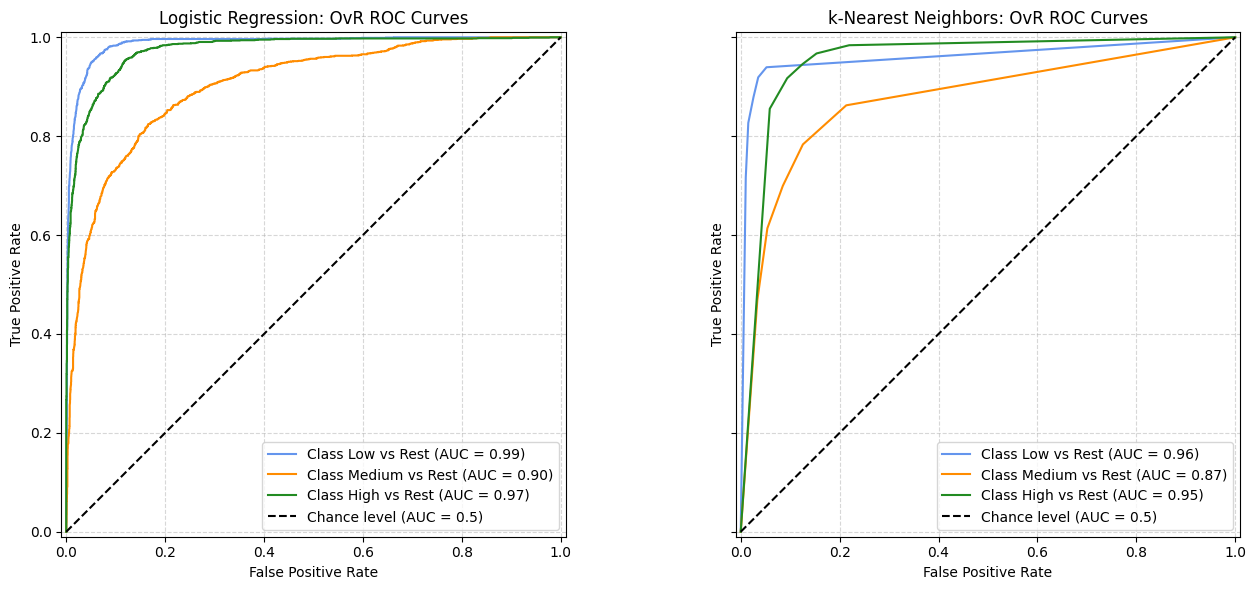

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import RocCurveDisplay

# 1. BINARIZE THE TEST LABELS FOR ONE-VS-REST PLOTTING
# This splits classes [0, 1, 2] into separate binary True/False columns
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# 2. GENERATE PREDICTED PROBABILITIES
y_prob_logreg = log_reg.predict_proba(X_test)
y_prob_knn = knn.predict_proba(X_test)

# 3. SET UP MATPLOTLIB AXES FOR SIDE-BY-SIDE PLOTS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
colors = ["cornflowerblue", "darkorange", "forestgreen"]

# --- PLOT 1: LOGISTIC REGRESSION ---
for class_id, color in zip(range(n_classes), colors):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, class_id],
        y_prob_logreg[:, class_id],
        name=f"Class {DEMAND_LABELS[class_id]} vs Rest",
        color=color,
        ax=ax1,
        plot_chance_level=(class_id == 2) # Draws the diagonal random-guess baseline once
    )
ax1.set_title("Logistic Regression: OvR ROC Curves")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.grid(True, linestyle="--", alpha=0.5)

# --- PLOT 2: k-NEAREST NEIGHBORS (k-NN) ---
for class_id, color in zip(range(n_classes), colors):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, class_id],
        y_prob_knn[:, class_id],
        name=f"Class {DEMAND_LABELS[class_id]} vs Rest",
        color=color,
        ax=ax2,
        plot_chance_level=(class_id == 2)
    )
ax2.set_title("k-Nearest Neighbors: OvR ROC Curves")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
